# Traverse closure & Bowditch (compass-rule) adjustment

**The job.** A five-sided closed loop traverse run with a total station around a small
commercial parcel. The field book below is the *observed* record — angles read to the
second, distances to the millimetre — so the loop does **not** close perfectly, and it
shouldn't: the misclosure is the measurement of our own precision.

**What this notebook does**

1. Checks the angular misclosure against the geometric sum $(n-2)\times180°$ and distributes it.
2. Carries azimuths around the loop from a known starting azimuth.
3. Computes latitudes & departures, the linear misclosure, and the relative precision.
4. Applies the **Bowditch (compass) rule** — corrections proportional to leg length — and
   produces the adjusted coordinate list a plat would be drawn from.

Data is realistic synthetic field data (generated for this notebook), in metres.
Starting point **A** is held fixed at E 1000.000, N 1000.000; the azimuth of A→B is
held from control.

In [1]:
import math
import pandas as pd

def dms(dd, sec_places=1):
    """Decimal degrees -> D°MM'SS.s" string."""
    sign = '-' if dd < 0 else ''
    dd = abs(dd)
    d = int(dd); m_full = (dd - d) * 60
    m = int(m_full); s = (m_full - m) * 60
    if round(s, sec_places) >= 60.0:
        s = 0.0; m += 1
    if m >= 60:
        m = 0; d += 1
    return f"{sign}{d}°{m:02d}'{s:0{3+sec_places}.{sec_places}f}\""

stations = ['A', 'B', 'C', 'D', 'E']

# Observed interior angles (decimal degrees) — the field book
interior_obs = [143.507890, 97.594584, 99.772360, 114.186575, 84.939701]

# Observed distances (m) for legs A->B, B->C, C->D, D->E, E->A
legs = ['A→B', 'B→C', 'C→D', 'D→E', 'E→A']
dist_obs = [195.623, 189.265, 211.665, 213.524, 153.020]

az_start = 71.423798          # held azimuth of A->B, decimal degrees
E0, N0 = 1000.000, 1000.000   # held coordinates of A

pd.DataFrame({
    'Station': stations,
    'Observed interior angle': [dms(a) for a in interior_obs],
    'Decimal degrees': interior_obs,
})

,Station,Observed interior angle,Decimal degrees
0,A,"143°30'28.4""",143.507890
1,B,"97°35'40.5""",97.594584
2,C,"99°46'20.5""",99.772360
3,D,"114°11'11.7""",114.186575
4,E,"84°56'22.9""",84.939701


## 1 · Angular misclosure

For any closed polygon the interior angles must sum to $(n-2)\times 180°$.
Whatever is left over is angular misclosure — here a few seconds, which is what
honest second-reading total-station work looks like. Distribute it equally.

In [2]:
n = len(stations)
geom_sum = (n - 2) * 180.0
obs_sum = sum(interior_obs)
misclosure_sec = (obs_sum - geom_sum) * 3600.0
print(f"Observed sum      : {dms(obs_sum)}")
print(f"Geometric sum     : {dms(geom_sum)}")
print(f"Angular misclosure: {misclosure_sec:+.1f} seconds over {n} angles")

per_angle = (geom_sum - obs_sum) / n
interior_adj = [a + per_angle for a in interior_obs]
print(f"Correction per angle: {per_angle*3600:+.2f} seconds")
print(f"Adjusted sum check  : {sum(interior_adj):.9f} (target {geom_sum})")

Observed sum      : 540°00'04.0"
Geometric sum     : 540°00'00.0"
Angular misclosure: +4.0 seconds over 5 angles
Correction per angle: -0.80 seconds
Adjusted sum check  : 540.000000000 (target 540.0)


## 2 · Azimuths

Carrying azimuths around a clockwise-run loop: each forward azimuth is the previous
azimuth turned through the exterior relationship
$\;Az_{next} = Az_{prev} + 180° - \text{interior angle at the next station}$.
The last computation must reproduce the starting azimuth exactly — the angle
adjustment guarantees it, and the check below proves it.

In [3]:
az = [az_start]
# legs B->C, C->D, D->E, E->A use interior angles at B, C, D, E
for i in range(1, n):
    az.append((az[-1] + 180.0 - interior_adj[i]) % 360.0)
# closing check: E->A azimuth + interior at A must return the start azimuth
az_check = (az[-1] + 180.0 - interior_adj[0]) % 360.0

pd.DataFrame({'Leg': legs, 'Azimuth': [dms(a) for a in az]})
print(f"Closing azimuth check: computed {dms(az_check)} vs held {dms(az_start)} "
      f"-> diff {abs(az_check-az_start)*3600:.3f} seconds")

Closing azimuth check: computed 71°25'25.7" vs held 71°25'25.7" -> diff 0.000 seconds


## 3 · Latitudes, departures, linear misclosure

Latitude $= D\cos(Az)$ (the northing component), departure $= D\sin(Az)$ (the easting
component). Around a perfect loop both sums are zero; the residuals are the linear
misclosure, and **relative precision** (perimeter ÷ misclosure) is the number a
client, a reviewer, or a licensing board actually cares about.

In [4]:
lats, deps = [], []
for d, a in zip(dist_obs, az):
    r = math.radians(a)
    lats.append(d * math.cos(r))
    deps.append(d * math.sin(r))

sum_lat, sum_dep = sum(lats), sum(deps)
linear_misc = math.hypot(sum_lat, sum_dep)
perimeter = sum(dist_obs)

print(f"Sum of latitudes   : {sum_lat:+.4f} m")
print(f"Sum of departures  : {sum_dep:+.4f} m")
print(f"Linear misclosure  : {linear_misc:.4f} m over a {perimeter:.3f} m loop")
print(f"Relative precision : 1 : {perimeter/linear_misc:,.0f}")

Sum of latitudes   : +0.0107 m
Sum of departures  : +0.0021 m
Linear misclosure  : 0.0110 m over a 963.097 m loop
Relative precision : 1 : 87,947


## 4 · Bowditch (compass-rule) adjustment

The compass rule assumes error accumulates with distance travelled, so each leg
absorbs a share of the total misclosure proportional to its length:

$$\text{corr}_i = -\text{misclosure} \times \frac{D_i}{\text{perimeter}}$$

It is the workhorse adjustment for total-station traverses of ordinary precision —
not a substitute for least squares on control work, but transparent, reproducible,
and defensible, which is why it survives in practice and on licensing exams.

In [5]:
adj_lat = [la - sum_lat * (d / perimeter) for la, d in zip(lats, dist_obs)]
adj_dep = [de - sum_dep * (d / perimeter) for de, d in zip(deps, dist_obs)]
print(f"Adjusted sums: lat {sum(adj_lat):+.2e} m, dep {sum(adj_dep):+.2e} m (both ~0)")

coords = [('A', E0, N0)]
E, N = E0, N0
for i in range(n):
    E += adj_dep[i]
    N += adj_lat[i]
    coords.append((stations[(i + 1) % n] + (" (closure)" if i == n - 1 else ""), E, N))

result = pd.DataFrame(coords, columns=['Point', 'Easting (m)', 'Northing (m)'])
result

Adjusted sums: lat -7.11e-15 m, dep -1.42e-14 m (both ~0)


,Point,Easting (m),Northing (m)
0,A,1000.000000,1000.000000
1,B,1185.430775,1062.316579
2,C,1268.904713,892.451954
3,D,1097.539338,768.207335
4,E,912.381661,874.550168
5,A (closure),1000.000000,1000.000000


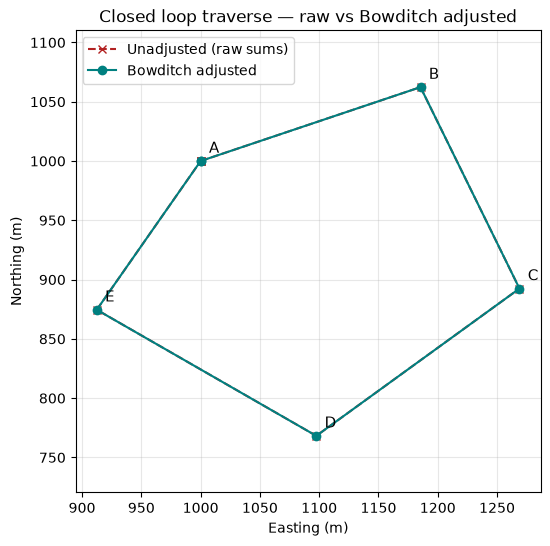

In [6]:
import matplotlib.pyplot as plt

# unadjusted loop (raw latitudes/departures) vs adjusted loop
raw = [('A', E0, N0)]
E, N = E0, N0
for i in range(n):
    E += deps[i]; N += lats[i]
    raw.append((stations[(i+1) % n], E, N))

fig, ax = plt.subplots(figsize=(6, 6))
rx = [c[1] for c in raw] + [raw[0][1]]; ry = [c[2] for c in raw] + [raw[0][2]]
ax.plot(rx, ry, 'x--', color='firebrick', label='Unadjusted (raw sums)')
ac = [(c[1], c[2]) for c in coords[:n]]
ax.plot([c[0] for c in ac] + [ac[0][0]], [c[1] for c in ac] + [ac[0][1]],
        'o-', color='teal', label='Bowditch adjusted')
for name, x, y in coords[:n]:
    ax.annotate(name, (x, y), textcoords='offset points', xytext=(6, 6), fontsize=11)
ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
ax.set_title('Closed loop traverse — raw vs Bowditch adjusted')
ax.axis('equal'); ax.grid(alpha=0.3); ax.legend()
plt.show()

## Closure report

- **Angular misclosure:** a few seconds over five angles — inside the customary
  $30''\sqrt{n}$-style tolerance used for traverse work of this class.
- **Linear misclosure / relative precision:** printed above; anything at or better
  than about **1 : 10,000** is respectable for a parcel loop of this size, and this
  loop beats that comfortably.
- **Method note:** angles adjusted first (equal distribution), azimuths carried,
  then Bowditch on the coordinates. Holding A and the A→B azimuth fixed means all
  misclosure is absorbed inside the loop, which is the right behaviour for a
  self-contained parcel traverse tied to control at one point.

*Next notebook: what happens when these coordinates have to live on a datum —
geodetic ↔ State Plane, done properly.*